In [1]:
%load_ext autoreload
%autoreload 2
from pathlib import Path
from halcyon.Simulators.GNWSimRunner import GNWSimRunner
from halcyon.Models.PhoenixModels import PhoenixOnlyAddLayers, PhoenixAddAndProdLayers
from halcyon.Models.CellBox import CellBox
from halcyon.Models.MechanisticModel import PyTorchODE
from halcyon.Models.HybridModel import HybridModel
from halcyon.Trainer import Trainer
from halcyon.FittedTrainerList import FittedTrainerList
from halcyon.Losses import MSELossPlusMachineLearningL2
from copy import deepcopy
from halcyon.Simulators.GNWSimRunner import SimulationResult

# import torch.multiprocessing as mp
import multiprocessing as mp

from halcyon.Trainer import run_training_job

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import logging

import torch
import numpy as np
import random

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 


logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

# Simulating data

In [2]:
# nr_genes_list = [32, 64, 128]
nr_genes_list = [10]
# nr_modules_list = [16, 5, 10]
nr_modules_list = [2]
sparsity_list = [0.02]
out_path = Path("../data/hybrid_model_first_tests") 

sim_outputs: list[SimulationResult] = []
for nr_genes in nr_genes_list: 
    for nr_modules in nr_modules_list: 
        for sparsity in sparsity_list: 
            gnw_sim = GNWSimRunner(
                settings_path=Path("../setting_files/gnw_testing_runs_settings.txt"),
            )
            generated_data_path = out_path / f"genes_{nr_genes}_modules_{nr_modules}_sparsity_{sparsity}"
            generated_data_path.mkdir(parents=True, exist_ok=True)
            network_name = 'my_network'
            sim_output = gnw_sim.run_simulation(
                n_genes=nr_genes,
                sparsity=sparsity,
                num_modules=nr_modules,
                network_name=network_name,
                output_path=generated_data_path,
                keep_self_interactions=False
            )
            sim_outputs.append(sim_output) 
sim_outputs

2025-12-03 16:08:33,820 - INFO - Generating network
2025-12-03 16:08:34,616 - INFO - Loading specified settings: ../setting_files/gnw_testing_runs_settings.txt
Done
Start network creation of type MODULAR_SCALEFREE
Removing autoregulatory interactions from my_network
Setting dynamical model for my_network

Random initialization of my_network
my_network: Node_0: (Node_3*Node_5~Node_1) + ~(Node_2*Node_7)
my_network: Node_1: ~(Node_6) + (Node_3) + (Node_8) + (Node_4)
my_network: Node_2: ~(Node_5*Node_3~Node_0) + ~(Node_7)
my_network: Node_3: (Node_4*Node_6) + (Node_1*Node_2)
my_network: Node_4: (Node_3) + ~(Node_6) + (Node_1)
my_network: Node_5: (Node_0) + ~(Node_2)
my_network: Node_6: (Node_4*Node_3~Node_1)
my_network: Node_7: (Node_2~Node_0) + ~(Node_5)
my_network: Node_8: ~(Node_1)
my_network: Node_9: (Node_3)
Writing file /lustre/BIF/nobackup/noord087/phd/HALCYON/notebooks/../data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02/my_network.xml

Thomas Schaffter (thomas.schaff.

[SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02'), network_name='my_network', nr_genes=10, nr_modules=2, sparsity=0.02, keep_self_interactions=False, network=<halcyon.RegulatoryNetwork.RegulatoryNetwork object at 0x7f7e3a27f820>)]

1


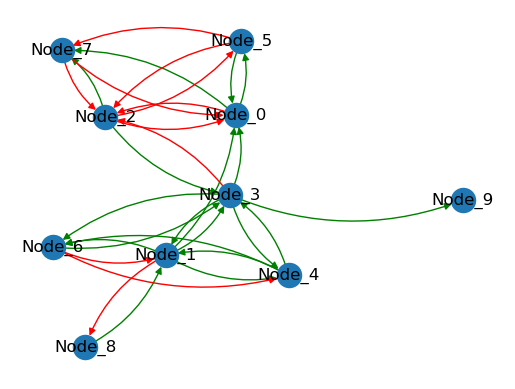

In [3]:
sim_output = sim_outputs[0]

from networkx import number_weakly_connected_components
print(number_weakly_connected_components(sim_output.network._graph))

sim_output.network.plot()
plt.show()

# Trainers (with different models) creation

In [4]:
train_jobs : list[Trainer] = []

## Mech model

In [5]:
# Generate MM from this
mm = PyTorchODE.from_sbml(sim_output.data_path / 'my_network.xml', condition_names=(), from_gnw=True, device='cpu')
# Select only genes from specific module
mm.select_genes([f'Node_{i}' for i in [0, 2 , 5, 7]])
# Fit MM on this data (skip for now?)
print(mm.modelled_gene_labels)
# Creating MM trainer even though it cannot be trained
mm_trainer = Trainer(
    mm,
    sim_output,
    batch_size=32,
    nr_training_steps=0,
    # optimizer_fn=lambda x: None
)

train_jobs.append(mm_trainer)
# mm_trainer.save(mm_trainer.save_path)

2025-12-03 16:08:49,020 - INFO - Loading SBML model from: /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02/my_network.xml


['Node_0', 'Node_2', 'Node_5', 'Node_7']


## ML and Hybrid model

In [6]:
expr_data = sim_output.get_no_noise_ko_timeseries_expressiondata()

# for hidden_size in [2, 5, 10]:
#     for do_only_pos in [True, False]:

for hidden_size in [10]:
    for do_only_pos in [True]:        
        ml_model = PhoenixAddAndProdLayers(
                    modelled_gene_labels=expr_data.genes,
                    hidden_size=hidden_size,
                    condition_names=expr_data.all_environments,
                    synthesis_only_positive=do_only_pos,
                    device='cuda:1'
            )

        # trainer = Trainer(
        #     ml_model,
        #     sim_output,
        #     batch_size=32,
        #     nr_training_steps=1000,
        # )

        # train_jobs.append(trainer)
        # Create hybrid model with MM and cellbox with add and prod
        hybrid_model = HybridModel(deepcopy(mm), deepcopy(ml_model), device='cpu')

        for model in [ml_model, hybrid_model]:
            # my_loss = MSELossPlusMachineLearningL2(lambda_param=0.5)
            trainer = Trainer(
                model,
                sim_output,
                batch_size=32,
                nr_training_steps=200,
                optimizer_kwargs = {'lr': 0.1}
            )
            train_jobs.append(trainer)

In [7]:
for job in train_jobs:
    print(job)
    print()

Training PyTorchODE on SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02'), network_name='my_network', nr_genes=10, nr_modules=2, sparsity=0.02, keep_self_interactions=False, network=<halcyon.RegulatoryNetwork.RegulatoryNetwork object at 0x7f7e3a27f820>). Saving to /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02/trained_trainer_PyTorchODE.pt

Training PhoenixAddAndProdLayers on SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02'), network_name='my_network', nr_genes=10, nr_modules=2, sparsity=0.02, keep_self_interactions=False, network=<halcyon.RegulatoryNetwork.RegulatoryNetwork object at 0x7f7e3a27f820>). Saving to /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02/trained_trainer_PhoenixAddAn

# Do training

In [8]:
# train_jobs[1].run_for_parallelisation_and_save()

In [9]:
# mp.set_start_method("spawn", force=True)
# with mp.Pool(processes=4) as pool:
#     pool.map(run_training_job, train_jobs)

# Plot results

In [10]:
train_jobs

[Training PyTorchODE on SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02'), network_name='my_network', nr_genes=10, nr_modules=2, sparsity=0.02, keep_self_interactions=False, network=<halcyon.RegulatoryNetwork.RegulatoryNetwork object at 0x7f7e3a27f820>). Saving to /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02/trained_trainer_PyTorchODE.pt,
 Training PhoenixAddAndProdLayers on SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02'), network_name='my_network', nr_genes=10, nr_modules=2, sparsity=0.02, keep_self_interactions=False, network=<halcyon.RegulatoryNetwork.RegulatoryNetwork object at 0x7f7e3a27f820>). Saving to /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02/trained_trainer_PhoenixAdd

In [11]:
# The above implementation works (but doesnt load from saved files)
result_list = FittedTrainerList.load_saved_jobs(train_jobs)

2025-12-03 16:08:53,299 - INFO - Loading from /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02/trained_trainer_PyTorchODE.pt
2025-12-03 16:08:53,325 - INFO - Loading from /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02/trained_trainer_PhoenixAddAndProdLayers_hidden_size_10_synthesis_only_positive_True_lr_0.1.pt
2025-12-03 16:08:53,332 - INFO - Loading from /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02/trained_trainer_HybridModel_hidden_size_10_synthesis_only_positive_True_lr_0.1.pt


## Single KO

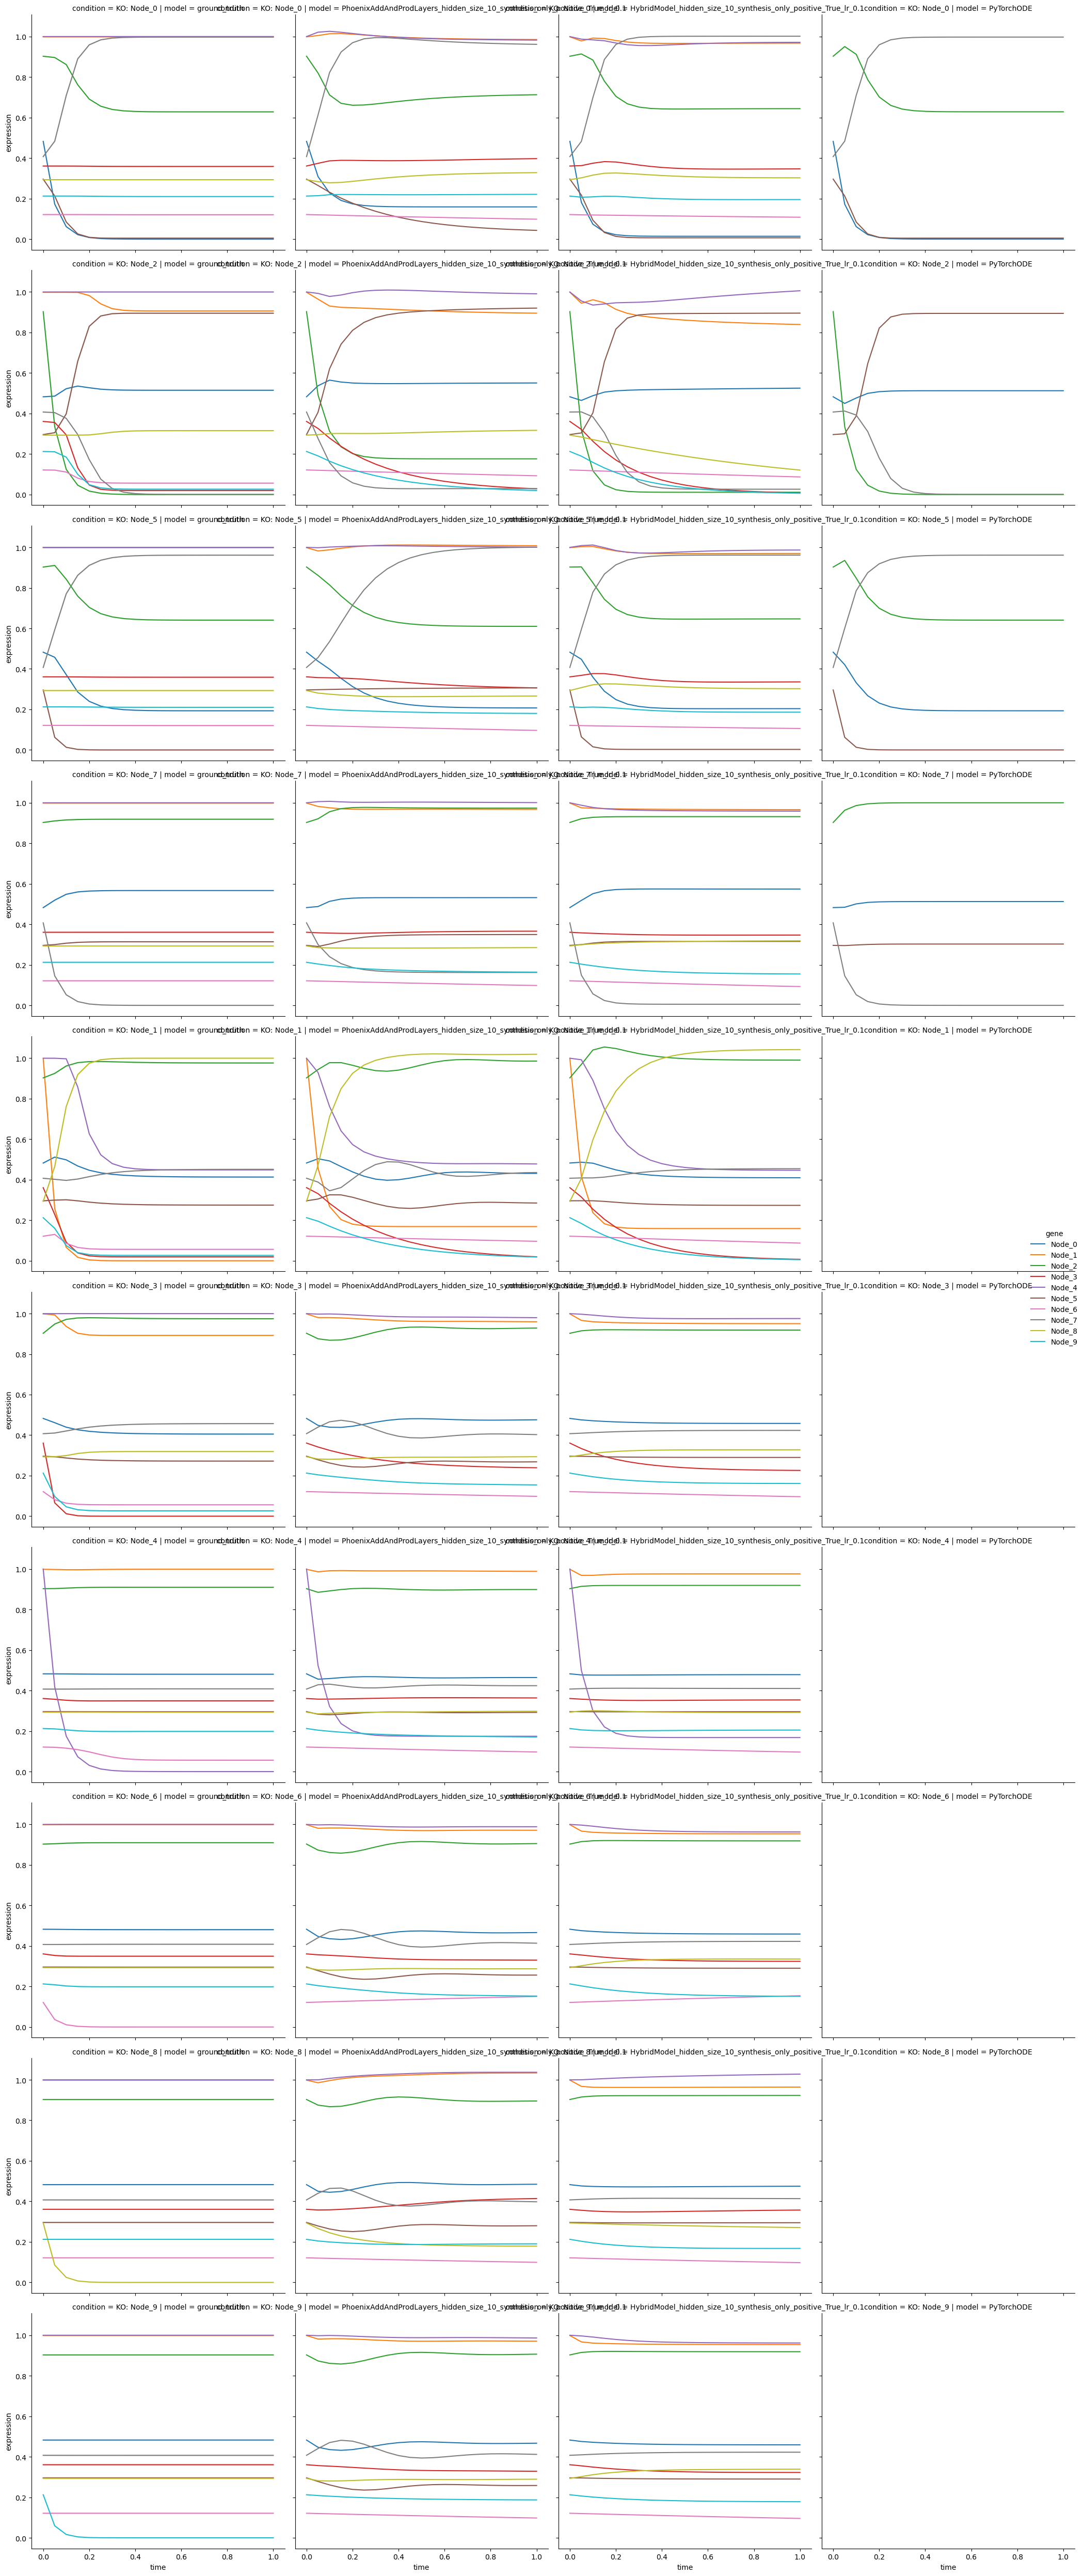

In [12]:
result_list.plot_single_ko();plt.tight_layout();plt.show()

## Double KO (unseen)

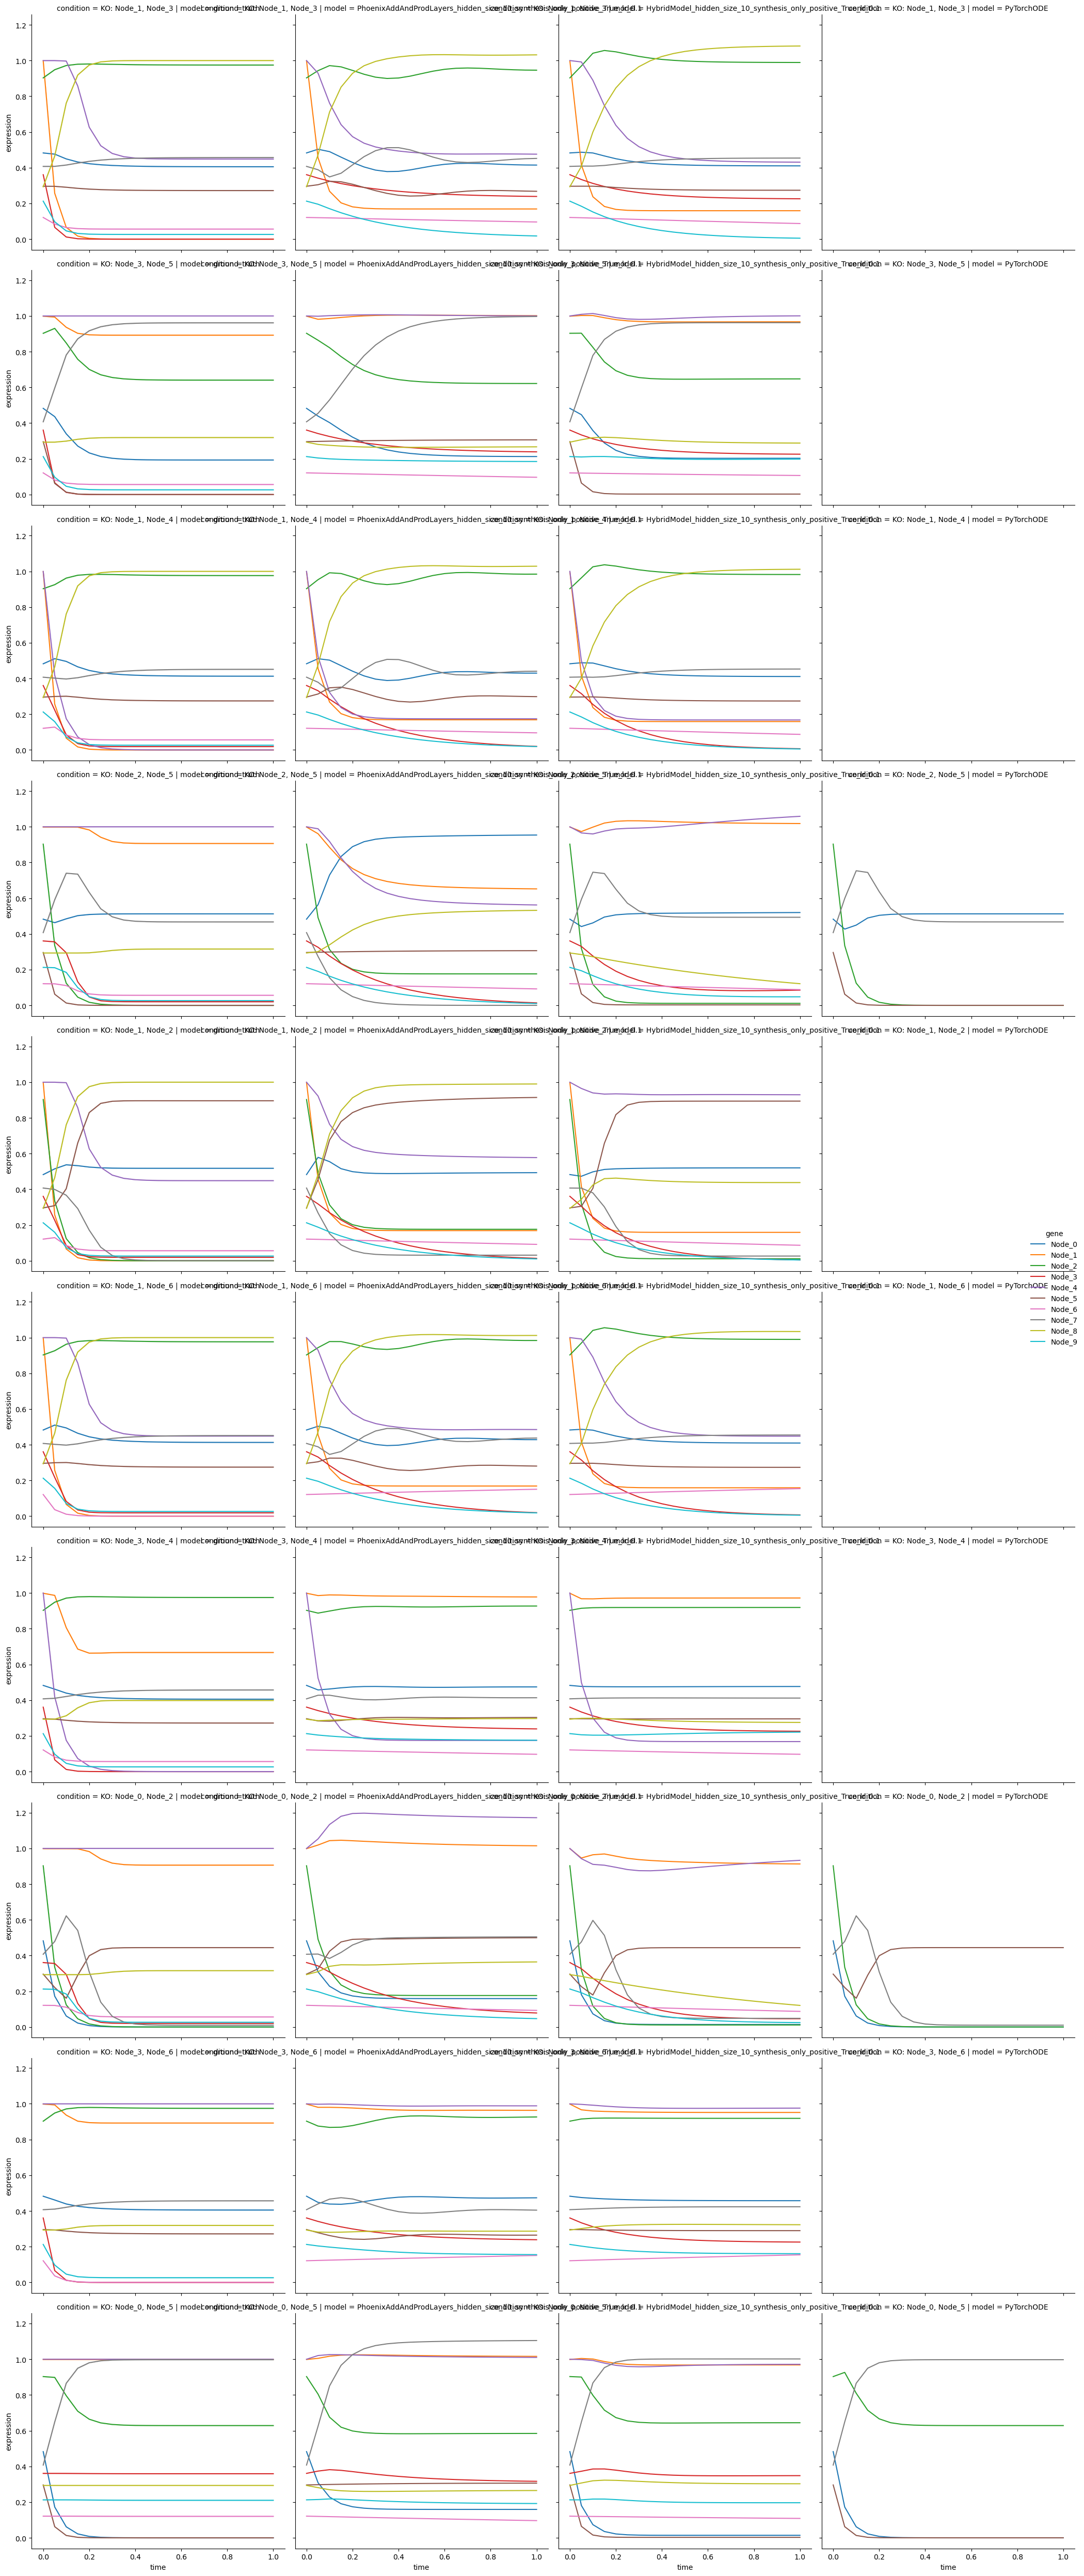

In [13]:
result_list.plot_double_ko();plt.tight_layout();plt.show()

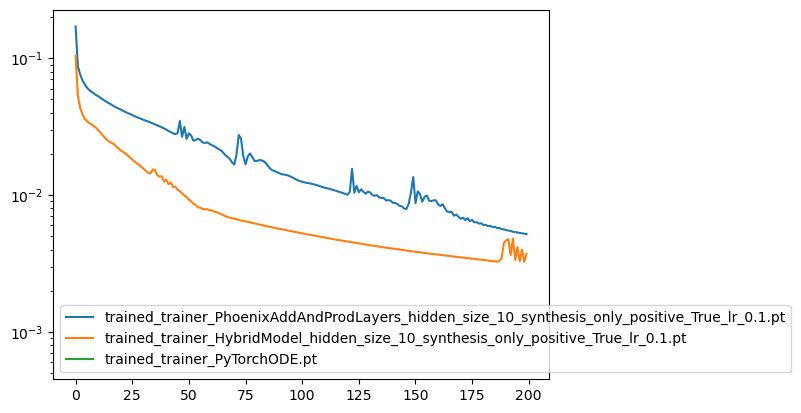

In [22]:
for result in result_list.trainer_list:
    # print(result.loss_history)
    plt.plot(result.loss_history, label=result.get_save_file_name())
plt.legend()
plt.yscale('log')
plt.show()

(<Figure size 640x480 with 2 Axes>,
 <Axes: title={'center': 'Final Loss Heatmap'}, xlabel='nr_genes', ylabel='model_overall_name'>)

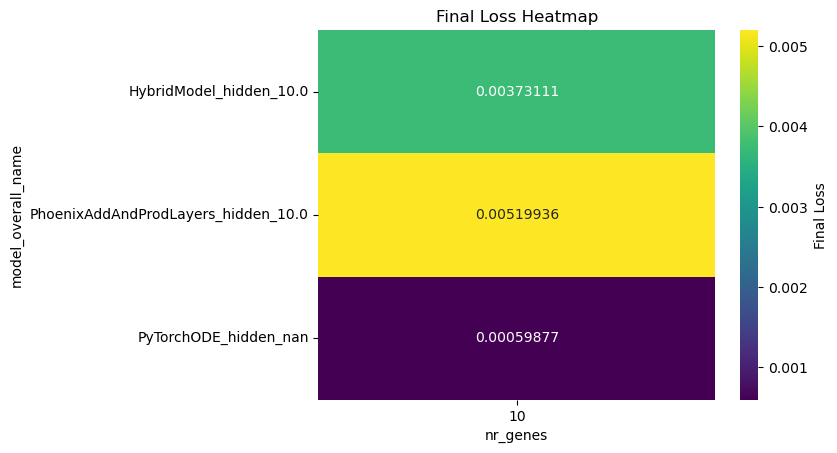

In [15]:
result_list.final_loss_heatmap()

## MSE visualisations

In [16]:
result_list.

SyntaxError: invalid syntax (3148847892.py, line 1)